In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

In [ ]:
df = pd.read_csv("/content/agriculture_yield_dataset.csv")

# Display first 5 rows
df.head()

,rainfall_mm,temperature_c,fertilizer_kg,irrigation_hours,soil_ph,crop_type,soil_type,yield_ton_per_hectare
0,588.6,18.6,242.4,6.5,6.5,Maize,Loamy,5.92
1,772.8,34.6,247.2,10.0,6.5,Maize,Sandy,6.24
2,970.9,36.3,168.4,7.3,6.4,Wheat,Sandy,4.77
3,611.7,19.0,121.7,3.7,6.0,Maize,Loamy,4.04
4,696.1,29.6,184.6,5.1,6.1,Cotton,Clay,5.17


Q1. Dataset Overview

Load the dataset and answer the following:

How many rows and columns are present?  

What are the names of all columns?

Display the first 10 records.

In [ ]:
# Number of rows and columns
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# First 10 records
print("\nFirst 10 Rows:")
print(df.head(10))


Shape: (1500, 8)

Columns:
['rainfall_mm', 'temperature_c', 'fertilizer_kg', 'irrigation_hours', 'soil_ph', 'crop_type', 'soil_type', 'yield_ton_per_hectare']

First 10 Rows:
   rainfall_mm  temperature_c  fertilizer_kg  irrigation_hours  soil_ph  \
0        588.6           18.6          242.4               6.5      6.5   
1        772.8           34.6          247.2              10.0      6.5   
2        970.9           36.3          168.4               7.3      6.4   
3        611.7           19.0          121.7               3.7      6.0   
4        696.1           29.6          184.6               5.1      6.1   
5        831.9           28.0          190.3               2.1      6.1   
6       1023.8           32.0          108.5               6.9      6.2   
7       1142.4           18.4          241.9               4.1      7.3   
8        810.4           36.4          164.8               9.9      6.5   
9       1085.5           29.4           89.3               8.3      5.8   


Q2. Data Types and Missing Values

Check the data type of each column.

Identify whether any missing values are present.  

If missing values exist, mention the affected columns.

In [ ]:
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

rainfall_mm              float64
temperature_c            float64
fertilizer_kg            float64
irrigation_hours         float64
soil_ph                  float64
crop_type                 object
soil_type                 object
yield_ton_per_hectare    float64
dtype: object

Missing Values:
rainfall_mm              0
temperature_c            0
fertilizer_kg            0
irrigation_hours         0
soil_ph                  0
crop_type                0
soil_type                0
yield_ton_per_hectare    0
dtype: int64


Q3. Descriptive Statistics

Generate summary statistics for all numerical features and answer:

Which feature has the highest mean value?  

Which feature has the highest standard deviation?

In [ ]:
stats = df.describe()

print(stats)

print("\nFeature with highest mean:")
print(stats.loc["mean"].idxmax())

print("\nFeature with highest standard deviation:")
print(stats.loc["std"].idxmax())

       rainfall_mm  temperature_c  fertilizer_kg  irrigation_hours  \
count  1500.000000    1500.000000    1500.000000       1500.000000   
mean    754.054667      27.749467     148.744067          5.403267   
std     255.097216       5.758101      56.990279          2.584329   
min     300.200000      18.000000      50.300000          1.000000   
25%     536.175000      22.600000      98.600000          3.200000   
50%     761.200000      27.700000     146.850000          5.400000   
75%     964.375000      32.600000     196.575000          7.600000   
max    1200.000000      38.000000     249.900000         10.000000   

           soil_ph  yield_ton_per_hectare  
count  1500.000000            1500.000000  
mean      6.759133               5.028793  
std       0.719742               0.968282  
min       5.500000               2.090000  
25%       6.100000               4.337500  
50%       6.800000               5.010000  
75%       7.400000               5.740000  
max       8.00000

Q4. Distribution Analysis

Create histograms for:

rainfall_mm  
temperature_c  
fertilizer_kg  
yield_ton_per_hectare  
Write 2–3 observations from each histogram.

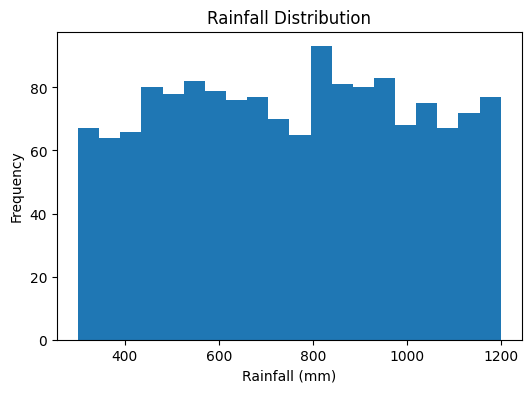

In [ ]:
plt.figure(figsize=(6,4))
plt.hist(df["rainfall_mm"], bins=20)
plt.title("Rainfall Distribution")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")
plt.show()

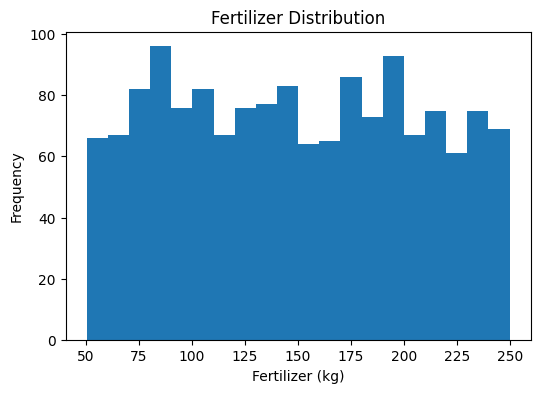

In [ ]:
plt.figure(figsize=(6,4))
plt.hist(df["fertilizer_kg"], bins=20)
plt.title("Fertilizer Distribution")
plt.xlabel("Fertilizer (kg)")
plt.ylabel("Frequency")
plt.show()

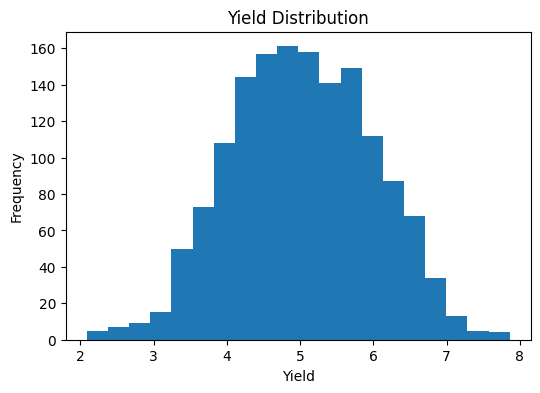

In [ ]:
plt.figure(figsize=(6,4))
plt.hist(df["yield_ton_per_hectare"], bins=20)
plt.title("Yield Distribution")
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.show()

Q5. Crop Type Analysis

Find the number of records for each crop type.  
Create a count plot (bar chart) for crop_type.  
Which crop appears most frequently?

crop_type
Cotton     311
Soybean    306
Wheat      303
Rice       293
Maize      287
Name: count, dtype: int64


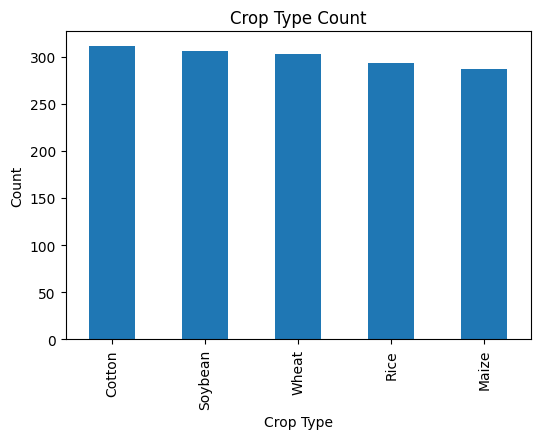

In [ ]:
print(df["crop_type"].value_counts())

plt.figure(figsize=(6,4))
df["crop_type"].value_counts().plot(kind="bar")
plt.title("Crop Type Count")
plt.xlabel("Crop Type")
plt.ylabel("Count")
plt.show()

In [ ]:
print(df["crop_type"].value_counts().idxmax())

Cotton


Q6. Soil Type Analysis

Find the frequency of each soil type.  
Create a count plot for soil_type.  
Which soil type is most common?

soil_type
Clay     534
Sandy    492
Loamy    474
Name: count, dtype: int64


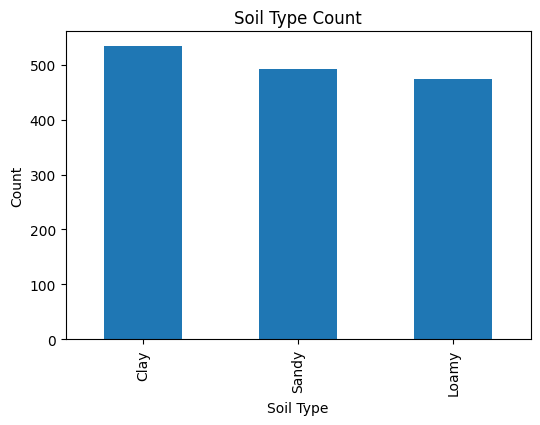

In [ ]:
# Frequency
print(df["soil_type"].value_counts())

# Plot
plt.figure(figsize=(6,4))
df["soil_type"].value_counts().plot(kind="bar")
plt.title("Soil Type Count")
plt.xlabel("Soil Type")
plt.ylabel("Count")
plt.show()

In [ ]:
print(df["soil_type"].value_counts().idxmax())

Clay


Q7. Yield Distribution

Create a histogram of yield_ton_per_hectare.
Answer:

Is the distribution approximately normal?  
Are there any noticeable outliers?

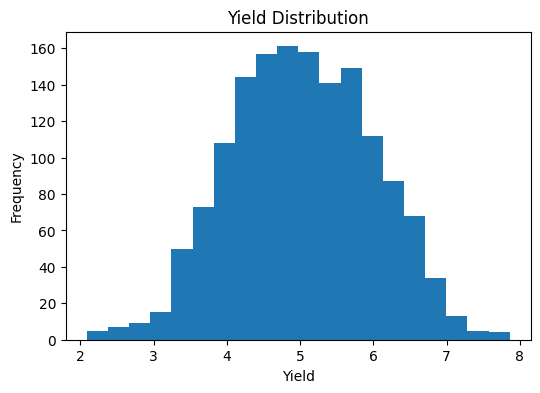

In [ ]:
plt.figure(figsize=(6,4))
plt.hist(df["yield_ton_per_hectare"], bins=20)
plt.title("Yield Distribution")
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.show()

Q8. Scatter Plot Analysis

Create scatter plots of:

1. rainfall_mm vs yield_ton_per_hectare  
2. fertilizer_kg vs yield_ton_per_hectare  
Based on the plots:

Which feature appears to have a stronger relationship with yield?

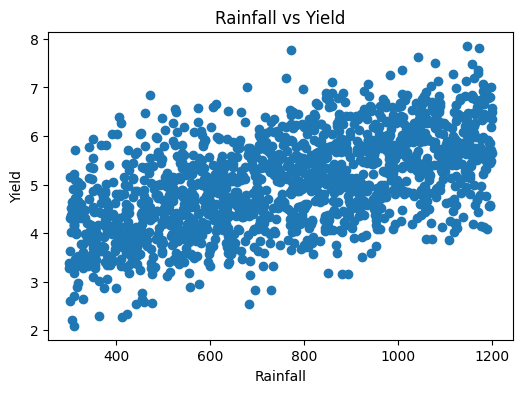

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(df["rainfall_mm"], df["yield_ton_per_hectare"])
plt.xlabel("Rainfall")
plt.ylabel("Yield")
plt.title("Rainfall vs Yield")
plt.show()

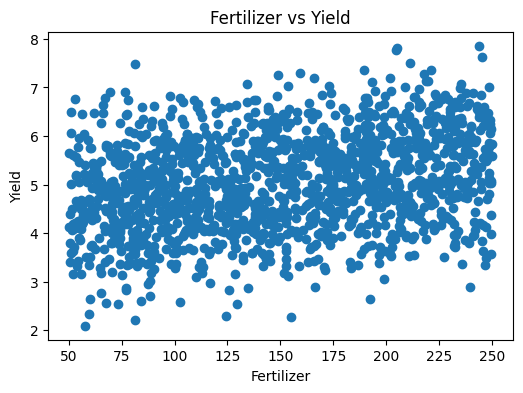

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(df["fertilizer_kg"], df["yield_ton_per_hectare"])
plt.xlabel("Fertilizer")
plt.ylabel("Yield")
plt.title("Fertilizer vs Yield")
plt.show()

Q9. Correlation Analysis

Generate a correlation matrix for numerical features.  
Create a heatmap.  
Identify the top three features most correlated with crop yield.

In [ ]:
corr = df.corr(numeric_only=True)
print(corr)

                       rainfall_mm  temperature_c  fertilizer_kg  \
rainfall_mm               1.000000       0.026721       0.002558   
temperature_c             0.026721       1.000000       0.037468   
fertilizer_kg             0.002558       0.037468       1.000000   
irrigation_hours          0.010877       0.007114      -0.010497   
soil_ph                   0.006916       0.001513       0.010001   
yield_ton_per_hectare     0.553704      -0.022559       0.278043   

                       irrigation_hours   soil_ph  yield_ton_per_hectare  
rainfall_mm                    0.010877  0.006916               0.553704  
temperature_c                  0.007114  0.001513              -0.022559  
fertilizer_kg                 -0.010497  0.010001               0.278043  
irrigation_hours               1.000000  0.009307               0.542664  
soil_ph                        0.009307  1.000000               0.024412  
yield_ton_per_hectare          0.542664  0.024412               1.000000 

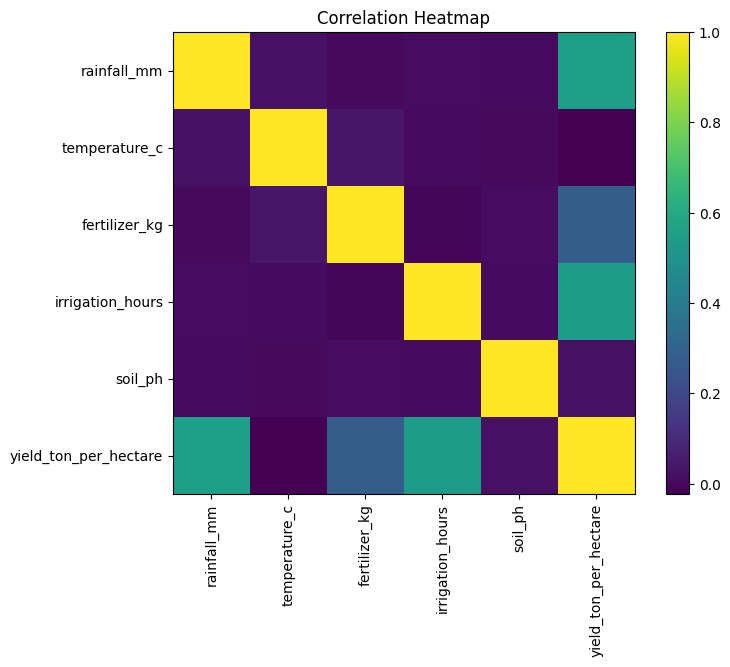

In [ ]:
plt.figure(figsize=(8,6))
plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
print(
    corr["yield_ton_per_hectare"]
    .sort_values(ascending=False)
)

yield_ton_per_hectare    1.000000
rainfall_mm              0.553704
irrigation_hours         0.542664
fertilizer_kg            0.278043
soil_ph                  0.024412
temperature_c           -0.022559
Name: yield_ton_per_hectare, dtype: float64


Q10. Group-Based Analysis

Calculate the average yield for:

Each crop type  
Each soil type  

Which crop and soil type have the highest average yield?

In [ ]:
crop_avg = df.groupby("crop_type")["yield_ton_per_hectare"].mean()
soil_avg = df.groupby("soil_type")["yield_ton_per_hectare"].mean()
print(crop_avg)
print()
print(soil_avg)

crop_type
Cotton     4.607299
Maize      4.897143
Rice       5.494744
Soybean    5.173431
Wheat      4.989472
Name: yield_ton_per_hectare, dtype: float64

soil_type
Clay     5.134326
Loamy    5.366519
Sandy    4.588882
Name: yield_ton_per_hectare, dtype: float64


In [ ]:
print("Best Crop:", crop_avg.idxmax())

print("Best Soil:", soil_avg.idxmax())

Best Crop: Rice
Best Soil: Loamy


Part C: Data Preparation

Q11. Feature Encoding

The dataset contains categorical variables.

Identify the categorical columns.  
Convert them into numerical form using One-Hot Encoding.  
Display the first five rows of the transformed dataset.

In [ ]:
#categorical columns
categorical_columns = df.select_dtypes(include="object").columns
print(categorical_columns)

#encoding
df_encoded = pd.get_dummies(df, columns=categorical_columns)

df_encoded.head()

Index(['crop_type', 'soil_type'], dtype='object')


,rainfall_mm,temperature_c,fertilizer_kg,irrigation_hours,soil_ph,yield_ton_per_hectare,crop_type_Cotton,crop_type_Maize,crop_type_Rice,crop_type_Soybean,crop_type_Wheat,soil_type_Clay,soil_type_Loamy,soil_type_Sandy
0,588.6,18.6,242.4,6.5,6.5,5.92,False,True,False,False,False,False,True,False
1,772.8,34.6,247.2,10.0,6.5,6.24,False,True,False,False,False,False,False,True
2,970.9,36.3,168.4,7.3,6.4,4.77,False,False,False,False,True,False,False,True
3,611.7,19.0,121.7,3.7,6.0,4.04,False,True,False,False,False,False,True,False
4,696.1,29.6,184.6,5.1,6.1,5.17,True,False,False,False,False,True,False,False


Q12. Feature Selection

Separate:

Input features (X)  
Target variable (y)  

Specify which column is being used as the target variable.

In [ ]:
X = df_encoded.drop("yield_ton_per_hectare", axis=1)
y = df_encoded["yield_ton_per_hectare"]
print("Target Variable: yield_ton_per_hectare")

Target Variable: yield_ton_per_hectare


Q13. Train-Test Split

Split the dataset into:

80% Training Data  
20% Testing Data  
Display the shape of:
X_train  
X_test  
y_train   
y_test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1200, 13)
X_test : (300, 13)
y_train: (1200,)
y_test : (300,)


Q14. Linear Regression Model

Train a Linear Regression model.  
Display the model coefficients and intercept.  
Which feature has the highest positive coefficient?

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
print("Intercept:")
print(model.intercept_)
print()

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print(coefficients)

Intercept:
1.9111026182800726

              Feature  Coefficient
0         rainfall_mm     0.002035
1       temperature_c    -0.009175
2       fertilizer_kg     0.004978
3    irrigation_hours     0.198327
4             soil_ph     0.004901
5    crop_type_Cotton    -0.386623
6     crop_type_Maize    -0.147693
7      crop_type_Rice     0.477369
8   crop_type_Soybean     0.095096
9     crop_type_Wheat    -0.038149
10     soil_type_Clay     0.062653
11    soil_type_Loamy     0.365627
12    soil_type_Sandy    -0.428280


In [ ]:
highest = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)
print(highest.head(1))

          Feature  Coefficient
7  crop_type_Rice     0.477369
